# 118 · why does `laser_cls` cost ~.12 ID even with per-laser P_l?
`cls-bothproj-v1` (freq_cls + laser_cls + band_proj + laser_proj, 23.6M) ends at ID .473 / OOD .272 IoU@.08 vs `s9-t2-ref-vase-200` .679 / .377 (34.9M).
With the projections on, the two [cls] costs are nearly additive: ref − .073 (freq side, `freqcls-bandproj-v1`) − .117 (laser side, `lasercls-laserproj-v1`) = .489 predicted vs .473 observed.
The frequency side is analysed in nb117; **this notebook is about the laser side and the combination**.

| | per laser: 18 band tokens → 1 | over lasers: 100 tokens → 1 latent |
|---|---|---|
| ref | gate + flatten + Linear | flatten + Linear(12,800 → 1024): one 128×1024 block per laser |
| `laser_cls` | (as ref) | a [cls] token, 2 laser blocks, LN + Linear(128 → 1024) |
| `+ laser_proj` (lp) | | a per-laser 128×128 P_l on each token before the laser stage (+1.6M) |

Hypotheses: **A** the 128-d cls is a rank bottleneck on the latent · **B** cls attention ≈ uniform, so cls ≈ mean of the laser tokens and *which laser* is lost ·
**C** it's just the −13M parameters · **D** what the failures look like · **E** what `freq_cls` does to the tokens `laser_cls` reads.
fp32, models on GPU (inference only), 500 train + 300 ID-eval + 100 unseen-position samples. Metric defs as nb113 (ID = id + multiple splits pooled per sample; OOD = rotated / cylinder / unseen-object / unseen-speaker / unseen-laser / lid).

In [1]:
import os, sys, math, re, json
os.environ["TQDM_DISABLE"] = "1"
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src9").exists())
sys.path.insert(0, str(ROOT / "src9")); os.chdir(ROOT)
import dataset as D9, score
from arch.transformer2 import Transformer2
torch.set_num_threads(8); torch.manual_seed(0); np.random.seed(0)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 90, "font.size": 10})
DEV = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False   # fp32 for analysis
# the 200-ep grid: short name -> run dir. flags are read from each run's args.json
GRID = {"ref": "s9-t2-ref-vase-200", "freqcls": "s9-t2-freqcls-vase-200", "freqcls+bp": "freqcls-bandproj-v1", "lasercls": "s9-t2-lasercls-vase-200",
        "lasercls+lp": "lasercls-laserproj-v1", "cls": "s9-t2-cls-vase-200", "cls+bp": "cls-bandproj-v1", "cls+lp": "cls-laserproj-v1", "cls+bp+lp": "cls-bothproj-v1"}
FLAGS = ("freq_cls", "laser_cls", "band_proj", "laser_proj")
ARGS = {r: {k: json.load(open(ROOT / "runs" / n / "args.json")).get(k, 0) for k in FLAGS} for r, n in GRID.items()}
LOAD = ["ref", "freqcls+bp", "lasercls", "lasercls+lp", "cls+bp", "cls+bp+lp"]          # the models this notebook loads
COL = {"ref": "tab:green", "freqcls": "tab:olive", "freqcls+bp": "tab:orange", "lasercls": "tab:blue", "lasercls+lp": "tab:cyan", "cls": "tab:gray",
       "cls+bp": "tab:pink", "cls+lp": "tab:brown", "cls+bp+lp": "tab:red"}
LCLS = ["lasercls", "lasercls+lp", "cls+bp+lp"]                                          # laser_cls models studied here
CAT = {(b, s): c for b, cs in D9.CATEGORIES.items() for c, ss in cs.items() for s in ss}
OOD = ["rotated", "cylinder", "unseen-object", "unseen-speaker", "unseen-laser", "lid"]
pd.DataFrame(ARGS).T

,freq_cls,laser_cls,band_proj,laser_proj
ref,0,0,0,0
freqcls,1,0,0,0
freqcls+bp,1,0,1,0
lasercls,0,1,0,0
lasercls+lp,0,1,0,1
cls,1,1,0,0
cls+bp,1,1,1,0
cls+lp,1,1,0,1
cls+bp+lp,1,1,1,1


## 0 · the 200-ep grid: size, fit, and whether it was still climbing
ID / OOD recomputed per sample from each run's saved ep200 eval outputs (the new runs don't log the pooled id/ood lines); train IoU = the end-of-run eval-mode pass over all training samples.

In [2]:
def sample_stats(p, y, thr=.08):
    """one eval sample: IoU, under/over-painting (as fractions of the true area), pred/true area, CoM error, and IoU after moving the pred onto the true CoM"""
    b = p > thr; ta = y.sum()
    s = dict(iou=(b & y).sum() / max((b | y).sum(), 1), miss=float(not (b & y).any()), under=(y & ~b).sum() / ta, over=(b & ~y).sum() / ta, area_ratio=b.sum() / ta)
    if b.any():
        cy, cb = np.argwhere(y).mean(0), np.argwhere(b).mean(0); s["com_err"] = np.linalg.norm(cy - cb) / 64     # box fractions
        dy, dx = np.round(cy - cb).astype(int)
        sh = np.zeros_like(b); H, W = b.shape
        sh[max(dy, 0):H + min(dy, 0), max(dx, 0):W + min(dx, 0)] = b[max(-dy, 0):H + min(-dy, 0), max(-dx, 0):W + min(-dx, 0)]
        s["shape_iou"] = (sh & y).sum() / max((sh | y).sum(), 1)
    else: s["com_err"], s["shape_iou"] = np.nan, 0.0
    return s

def eval_frame(run, ep, full=True):
    rows = []
    for f in sorted((ROOT / "runs" / run / "outputs_history/eval").glob(f"*/*/ep{ep:04d}-ba*.pt")):
        d = torch.load(f, weights_only=False, map_location="cpu"); p, info = d["mask_pred"].float().numpy(), d["info"]
        box, split = f.parent.parent.name, f.parent.name; cat = CAT.get((box, split)); cat = "id" if cat == "multiple" else cat
        for i in range(len(p)):
            y = score.truth(info["experiment"][i], info["sample_id"][i], int(info["position_id"][i]), int(info["speaker"][i]), *p.shape[-2:]) > .5
            if not y.any(): continue
            b = p[i] > .08
            s = sample_stats(p[i], y) if full else dict(iou=(b & y).sum() / max((b | y).sum(), 1))
            rows.append(dict(box=box, split=split, cat=cat, pos=int(info["position_id"][i]), **s))
    return pd.DataFrame(rows)

def id_ood(df): return df.iou[df.cat == "id"].mean(), df.iou[df.cat.isin(OOD)].mean()
EV = {r: eval_frame(n, 200) for r, n in GRID.items()}                                      # per-sample stats at ep200
CURVE = {r: {ep: id_ood(eval_frame(n, ep, full=False)) for ep in (50, 100, 150)} | {200: id_ood(EV[r])} for r, n in GRID.items()}

def from_log(run):
    txt = (ROOT / "runs" / run / "logs-rank0.txt").read_text()
    last = lambda k: float(re.findall(rf"{re.escape(k)}: ([0-9.]+)", txt)[-1])
    loss = [float(v) for v in re.findall(r"Train loss/train/total: ([0-9.]+)", txt)]
    return dict(train_iou=last("Eval metrics/train/iou08"), train_com=last("Eval metrics/train/com_err"), loss_end=np.mean(loss[-20:]), loss=loss)
LOG = {r: from_log(n) for r, n in GRID.items()}
SD = {r: torch.load(ROOT / f"runs/{GRID[r]}/checkpoints/ep200-ba2000-rank0.pt", weights_only=False, map_location="cpu")["state"]["model"] for r in GRID}
def n_params(sd, pat=""): return sum(v.numel() for k, v in sd.items() if pat in k and not any(b in k for b in ("cum_", "running_", "num_batches")))

T = pd.DataFrame({r: dict(**ARGS[r], params_M=n_params(SD[r]) / 1e6, ID=CURVE[r][200][0], OOD=CURVE[r][200][1], train_IoU=LOG[r]["train_iou"],
                          train_minus_ID=LOG[r]["train_iou"] - CURVE[r][200][0], ID_ep150=CURVE[r][150][0], ID_gain_150_200=CURVE[r][200][0] - CURVE[r][150][0],
                          loss_end=LOG[r]["loss_end"]) for r in GRID}).T
print("200-ep grid (ID/OOD recomputed from the saved ep200 eval outputs)"); display(T.astype(float).round(3))

200-ep grid (ID/OOD recomputed from the saved ep200 eval outputs)


,freq_cls,laser_cls,band_proj,laser_proj,params_M,ID,OOD,train_IoU,train_minus_ID,ID_ep150,ID_gain_150_200,loss_end
ref,0.0,0.0,0.0,0.0,34.923,0.679,0.377,0.803,0.124,0.670,0.009,0.233
freqcls,1.0,0.0,0.0,0.0,34.611,0.562,0.309,0.644,0.083,0.531,0.030,0.490
freqcls+bp,1.0,0.0,1.0,0.0,34.896,0.606,0.344,0.698,0.092,0.570,0.036,0.399
lasercls,0.0,1.0,0.0,0.0,21.947,0.541,0.308,0.652,0.111,0.514,0.027,0.448
lasercls+lp,0.0,1.0,0.0,1.0,23.598,0.561,0.305,0.683,0.122,0.542,0.019,0.367
cls,1.0,1.0,0.0,0.0,21.635,0.354,0.186,0.412,0.058,0.307,0.047,0.923
cls+bp,1.0,1.0,1.0,0.0,21.920,0.452,0.242,0.532,0.080,0.421,0.031,0.669
cls+lp,1.0,1.0,0.0,1.0,23.286,0.382,0.202,0.441,0.059,0.358,0.024,0.781
cls+bp+lp,1.0,1.0,1.0,1.0,23.571,0.473,0.272,0.552,0.080,0.455,0.018,0.560


## load the checkpoints and the samples
`encode` is the encoder written out so it can keep intermediates and be intervened on (uniform cls attention, shuffled laser slots); it's checked against the real forward.

In [3]:
NAMES = None
def build(r):
    sd = SD[r]; nobj, K = sd["object_head.2.weight"].shape[0], sd["n_objects_head.2.weight"].shape[0] - 1
    info = dict(freq_range=(100.0, 1000.0), n_freqs=1170, n_laser_rows=10, n_laser_cols=10, n_channels=2, boxes=NAMES,
                cum_mean=sd["encoder.cum_mean"], cum_var=sd["encoder.cum_std"].pow(-2), objects=[str(i) for i in range(nobj + 1)], n_objects=list(range(K + 1)))
    m = Transformer2(info, **ARGS[r]); m.load_state_dict(sd, strict=True)
    return m.eval().to(DEV)

ev = {"id": [], "unseen-position": []}
for f in sorted((ROOT / f"runs/{GRID['ref']}/outputs_history/eval").glob("*/*/ep0200-ba*.pt")):
    c = CAT.get((f.parent.parent.name, f.parent.name)); c = "id" if c == "multiple" else c
    if c not in ev: continue
    info = torch.load(f, weights_only=False, map_location="cpu")["info"]
    ev[c] += [(info["experiment"][i], int(info["sample_id"][i]), int(info["position_id"][i]), int(info["speaker"][i])) for i in range(len(info["experiment"]))]
samples, idxs = D9.load_splits()
metas = list(samples.values())
tr = [(m["experiment"], int(m["sample_id"]) if m["sample_id"].isdigit() else -1, int(m["position_id"]), int(m["speaker"])) for m in (metas[i] for i in idxs["train"]) if m["n_objects"] > 0]
pick = lambda L, n: [L[i] for i in np.random.choice(len(L), n, replace=False)]
SEL = [("train", s) for s in pick(tr, 500)] + [("id", s) for s in pick(ev["id"], 300)] + [("unseen-position", s) for s in pick(ev["unseen-position"], 100)]
X, BOXN, Y, NOBJ, OBJ = [], [], [], [], []
for _, (exp, sid, pos, spk) in SEL:
    d = score.sample_dir(exp, sid, pos, spk); meta = D9.load_meta(d)
    s = D9.load_fft(d, meta, "tukey").abs(); X.append((s / s.std()).float()); BOXN.append(meta["box"]); NOBJ.append(meta["n_objects"])
    OBJ.append("+".join(sorted(meta["objects"]))); Y.append(score.truth(exp, sid, pos, spk, 64, 64))
X, Y, NOBJ, OBJ = torch.stack(X), np.stack(Y), np.array(NOBJ), np.array(OBJ)
GROUP = np.array([g for g, _ in SEL]); N = len(SEL)
NAMES = sorted(set(BOXN)); BOX = torch.tensor([NAMES.index(b) for b in BOXN])
G = {g: np.where(GROUP == g)[0] for g in ["train", "id", "unseen-position"]}
TR, ID, UP = G["train"], G["id"], G["unseen-position"]
M = {r: build(r) for r in LOAD}
print("X", tuple(X.shape), {g: len(v) for g, v in G.items()}, "boxes", NAMES, "objects", sorted(set(OBJ)))

2026_09_27_gastronorm_four_objs: 6155 samples


2026_10_05_green_plastic_four_objs: 5736 samples


2026_10_11_cardboard_four_objs: 7228 samples


split                                          samples    positions
-------------------------------------------  ---------  -----------
train                                            11219         3032
eval/gastro/vase                                   135           45
eval/gastro/candle                                 156           52
eval/gastro/cube                                   147           49
eval/gastro/cube-unseen-speaker-baseline           105           35
eval/gastro/cube-unseen-speaker-unseen              35           35
eval/gastro/soap-dispenser                         146           49
eval/gastro/cube-vase                               27            9
eval/gastro/two-cubes                               42           14
eval/gastro/cube-with-lid                           15            5
eval/gastro/cube-without-lid                        15            5
eval/gastro/cylinder-1000g                          27            9
eval/gastro/cylinder-500g                       

tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]


tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400, 450), (450, 500), (500, 550), (550, 600), (600, 650), (650, 700), (701, 750), (751, 800), (801, 850), (851, 900), (901, 950), (951, 1000)]
tokenize freqs [100, 1000] Hz of 1170 bins to 18 bands of 65 bins: [(100, 149), (150, 199), (200, 249), (250, 299), (300, 349), (350, 399), (400,

X (900, 100, 1170, 2) {'train': 500, 'id': 300, 'unseen-position': 100} boxes ['cardboard', 'gastronorm', 'green-plastic'] objects [np.str_('candle'), np.str_('cylinder-1000g'), np.str_('cylinder-100g'), np.str_('cylinder-200g'), np.str_('cylinder-500g'), np.str_('glass-cup'), np.str_('green-cube+red-cube'), np.str_('red-cube'), np.str_('red-cube+vase'), np.str_('soap dispenser'), np.str_('vase')]


In [4]:
def block(blk, x, uniform_cls=False):
    """Block.forward written out: returns (new x, attention weights (N,H,T,T)). uniform_cls: the token at position 0 reads all other tokens equally"""
    N, T, D = x.shape
    q, k, v = blk.qkv(blk.n1(x)).view(N, T, 3, blk.h, -1).permute(2, 0, 3, 1, 4)
    a = (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)
    if uniform_cls: a = a.clone(); a[:, :, 0, 1:] = (1 - a[:, :, 0, :1]) / (T - 1)
    x = x + blk.o((a @ v).transpose(1, 2).reshape(N, T, D))
    return x + blk.mlp(blk.n2(x)), a

@torch.no_grad()
def encode(m, x, bx, uniform=(), perm=None):
    """the transformer2 encoder written out, keeping intermediates. uniform: laser-stage layers whose laser_cls reads the lasers uniformly.
    perm: (L,) permutation: laser l's slot gets laser perm[l]'s content (its own laser identity/position embedding stays)"""
    e, fe, le = m.encoder, m.encoder.freq_enc, m.encoder.laser_enc
    B, L = x.shape[:2]
    xn = e.normalize(x, bx).reshape(B, L, 18, -1)
    laser = e.laser_emb + e.laser_pos(e.laser_fourier)                                      # (L,128)
    t = (torch.einsum("blpi,pid->blpd", xn, fe.embed_w) + fe.embed_b) if fe.band_proj else fe.embed(xn)
    t = (t + fe.freq_band_emb(e.freq_band_logf[:, None])[None, None] + laser[None, :, None] + fe.box_emb(bx)[:, None, None]).flatten(0, 1)
    out = dict(energy=xn.mean(-1))                                                          # (B,L,18) z-scored input energy per laser and band
    if fe.cls:
        t = torch.cat([fe.freq_cls.expand(len(t), 1, -1), t], 1); FA = []
        for blk in fe.freqs: t, a = block(blk, t); FA.append(a[:, :, 0, 1:])
        out["freq_attn"] = torch.stack(FA, 1).view(B, L, len(FA), fe.heads, 18); raw = t[:, 0].view(B, L, -1)
    else:
        for blk in fe.freqs: t, _ = block(blk, t)
        t = t.view(B, L, 18, -1); k = fe.pool_k(fe.pool_norm(t)).view(B, L, 18, fe.heads, -1)
        g = torch.einsum("blphe,he->blhp", k, fe.pool_q).div(math.sqrt(k.shape[-1])).softmax(-1).mean(2) * 18
        raw = fe.pool_o((t * g[..., None]).reshape(B, L, -1))
    out["raw"] = raw                                                                        # per-laser token out of the freq stage
    if e.laser_proj: raw = torch.einsum("bld,lde->ble", raw, e.proj_w) + e.proj_b
    out["proj"] = raw                                                                       # after P_l (= raw without laser_proj)
    if perm is not None: raw = raw[:, perm]
    z = raw + laser; out["tok"] = z                                                         # laser-stage input
    if le.cls: z = torch.cat([le.laser_cls.expand(B, 1, -1), z], 1)
    LA = []
    for i, blk in enumerate(le.lasers): z, a = block(blk, z, le.cls and i in uniform); LA.append(a[:, :, 0, 1:] if le.cls else a.mean(2))
    out["laser_attn"] = torch.stack(LA, 1)                                                  # (B,layers,H,100): what laser_cls reads (cls) / attention each laser receives (ref)
    out["ztok"] = z[:, 1:] if le.cls else z                                                 # laser tokens after the laser stage
    if le.cls: out["c"] = z[:, 0]                                                           # the 128-d laser_cls output
    out["emb"] = le.to_emb(z[:, 0]) if le.cls else le.to_emb(z)                             # the 1024-d decoder latent
    out["mask"] = m.decoder(out["emb"])[:, 0].sigmoid()
    return out

def run(m, idx=None, bs=50, keep=None, **kw):
    idx = np.arange(N) if idx is None else np.asarray(idx); outs = []
    for i in range(0, len(idx), bs):
        o = encode(m, X[idx[i:i + bs]].to(DEV), BOX[idx[i:i + bs]].to(DEV), **kw)
        outs.append({k: v.cpu() for k, v in o.items() if keep is None or k in keep})
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}

def iou(P, idx, thr=.08): return np.array([((P[j] > thr) & (Y[i] > .5)).sum() / max(((P[j] > thr) | (Y[i] > .5)).sum(), 1) for j, i in enumerate(idx)])
with torch.no_grad():                                                                       # encode == the real forward
    for r, m in M.items():
        assert torch.allclose(m.decoder(m.encoder(X[:4].to(DEV), BOX[:4].to(DEV)))[:, 0].sigmoid().cpu(), run(m, np.arange(4))["mask"], atol=1e-4), r
O = {r: run(m) for r, m in M.items()}
chk = pd.DataFrame({r: {g: iou(O[r]["mask"][ix].numpy(), ix).mean() for g, ix in G.items()} | {"ID (log)": T.loc[r, "ID"], "train IoU (log)": T.loc[r, "train_IoU"]} for r in LOAD}).T
print("IoU@.08 on the samples used here (vs the logged numbers)"); display(chk.round(3))

IoU@.08 on the samples used here (vs the logged numbers)


,train,id,unseen-position,ID (log),train IoU (log)
ref,0.812,0.685,0.641,0.679,0.803
freqcls+bp,0.710,0.612,0.588,0.606,0.698
lasercls,0.654,0.549,0.535,0.541,0.652
lasercls+lp,0.691,0.569,0.451,0.561,0.683
cls+bp,0.545,0.433,0.395,0.452,0.532
cls+bp+lp,0.565,0.470,0.427,0.473,0.552


## A · is the 128-d cls a rank bottleneck on the 1024-d latent?
With `laser_cls` the latent is LN + Linear(128 → 1024) of one vector, so its rank is ≤ 128. **A1** how many directions each latent actually uses (PCA over the 900 samples).
**A2 (causal)**: keep only the top-k principal directions of each latent (PCA fit on train samples), decode, score. If ref truncated to 128 directions keeps its IoU, a 128-d
bottleneck is *not* what limits `laser_cls` — what goes into those 128 dims is.

A1 · the 1024-d decoder latent over all 900 samples: how many directions does it use?


,part_ratio,k50,k90,k99,rank_bound
ref,27.224016,12.0,72.0,350.0,1024.0
freqcls+bp,19.130182,7.0,43.0,239.0,1024.0
lasercls,17.424240,6.0,31.0,87.0,128.0
lasercls+lp,11.306200,4.0,19.0,70.0,128.0
cls+bp,15.826421,6.0,24.0,74.0,128.0
cls+bp+lp,10.430346,4.0,15.0,59.0,128.0


A2 · ID IoU@.08 when the latent is projected onto its top-k principal directions (fit on train samples), then decoded


,2,4,8,16,32,64,128,256
ref,0.110,0.144,0.240,0.352,0.501,0.625,0.669,0.678
freqcls+bp,0.113,0.115,0.202,0.286,0.473,0.567,0.599,0.605
lasercls,0.112,0.196,0.289,0.379,0.486,0.532,0.549,0.549
lasercls+lp,0.090,0.217,0.388,0.501,0.541,0.563,0.569,0.569
cls+bp,0.052,0.151,0.262,0.347,0.401,0.426,0.433,0.433
cls+bp+lp,0.106,0.231,0.315,0.417,0.454,0.466,0.470,0.470


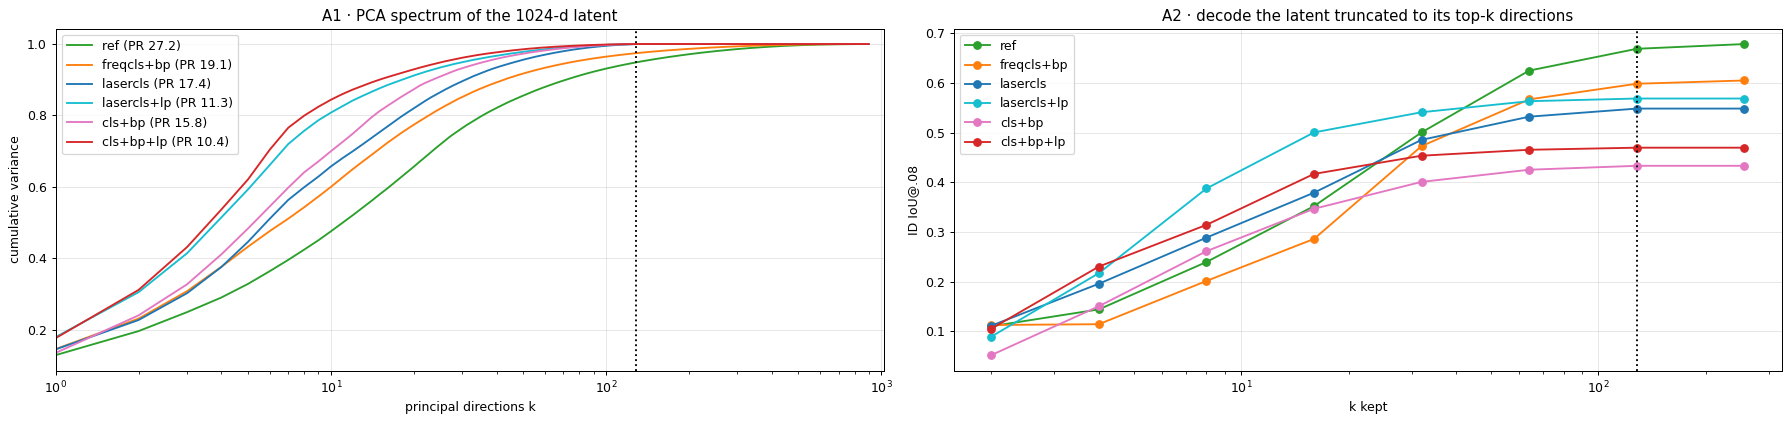

In [5]:
def pca(Z, fit_idx):
    """PCA fit on rows fit_idx: (mean, components (k,D), variances)"""
    mu = Z[fit_idx].mean(0); U, s, Vt = torch.linalg.svd((Z[fit_idx] - mu).double(), full_matrices=False)
    return mu, Vt.float(), (s ** 2 / (len(fit_idx) - 1)).float()
def spectrum_stats(v):
    c = (v / v.sum()).cumsum(0)
    return dict(part_ratio=(v.sum() ** 2 / (v ** 2).sum()).item(), k50=int((c < .5).sum()) + 1, k90=int((c < .9).sum()) + 1, k99=int((c < .99).sum()) + 1)
A1 = {}; SPEC = {}
for r in LOAD:
    _, _, v = pca(O[r]["emb"], np.arange(N)); SPEC[r] = v; A1[r] = spectrum_stats(v) | dict(rank_bound=1024 if not ARGS[r]["laser_cls"] else 128)
print("A1 · the 1024-d decoder latent over all 900 samples: how many directions does it use?"); display(pd.DataFrame(A1).T)

# A2 · causal: keep only the top-k principal directions of the latent (fit on the 500 train samples), decode, score
KS = [2, 4, 8, 16, 32, 64, 128, 256, 1024]
A2 = {}
for r in LOAD:
    Z = O[r]["emb"]; mu, V, _ = pca(Z, TR); A2[r] = {}
    for k in KS:
        if k > len(V): continue
        Zk = mu + (Z - mu) @ V[:k].T @ V[:k]
        with torch.no_grad(): P = torch.cat([M[r].decoder(Zk[i:i + 100].to(DEV))[:, 0].sigmoid().cpu() for i in range(0, N, 100)]).numpy()
        A2[r][k] = iou(P[ID], ID).mean()
A2 = pd.DataFrame(A2).T
print("A2 · ID IoU@.08 when the latent is projected onto its top-k principal directions (fit on train samples), then decoded"); display(A2.round(3))

fig, axs = plt.subplots(1, 2, figsize=(20, 4.8))
for r in LOAD:
    v = SPEC[r]; axs[0].plot(np.arange(1, len(v) + 1), (v / v.sum()).cumsum(0), color=COL[r], label=f"{r} (PR {A1[r]['part_ratio']:.1f})")
    axs[1].plot(A2.columns, A2.loc[r], "o-", color=COL[r], label=r)
axs[0].set(xscale="log", xlabel="principal directions k", ylabel="cumulative variance", title="A1 · PCA spectrum of the 1024-d latent", xlim=(1, 1024)); axs[0].axvline(128, color="k", ls=":")
axs[1].set(xscale="log", xlabel="k kept", ylabel="ID IoU@.08", title="A2 · decode the latent truncated to its top-k directions"); axs[1].axvline(128, color="k", ls=":")
for ax in axs: ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

**A3 · what does the latent know?** Linear (ridge) probes, fit on train samples, scored on ID: CoM (single-object), the mask in its top-32 PCs (PCs 1-4 = coarse blob position/size,
5-32 = finer shape/position), log area, object identity.

In [6]:
def ridge_fit(Xtr, Ytr, lam):
    """standardized ridge; primal if features <= rows else dual. returns predict(X)"""
    mu, sd, ym = Xtr.mean(0), Xtr.std(0) + 1e-6, Ytr.mean(0); A = ((Xtr - mu) / sd).double(); Yc = (Ytr - ym).double(); n, p = A.shape
    if p <= n: W = torch.linalg.solve(A.T @ A + lam * n * torch.eye(p, dtype=torch.float64), A.T @ Yc)
    else: W = A.T @ torch.linalg.solve(A @ A.T + lam * n * torch.eye(n, dtype=torch.float64), Yc)
    return lambda Xte: (ym.double() + ((Xte - mu) / sd).double() @ W).float()
def r2(pred, Yte): return 1 - (Yte - pred).pow(2).sum(0) / (Yte - Yte.mean(0)).pow(2).sum(0)
def probe(feat, target, tr_idx, te_idx, lams=(1e-3, 1e-2, 1e-1, 1, 10)):
    """ridge from feat to target, lambda picked on the last 20% of tr_idx -> (prediction on te_idx, per-target R² on te_idx)"""
    f, t = torch.as_tensor(feat).float(), torch.as_tensor(target).float()
    n = int(len(tr_idx) * .8); a, b = tr_idx[:n], tr_idx[n:]
    lam = max(lams, key=lambda l: r2(ridge_fit(f[a], t[a], l)(f[b]), t[b]).mean().item())
    pred = ridge_fit(f[tr_idx], t[tr_idx], lam)(f[te_idx]); return pred, r2(pred, t[te_idx])

# targets
com = np.stack([np.argwhere(y > .5).mean(0) / 64 if (y > .5).any() else [np.nan, np.nan] for y in Y])          # (N,2) row, col in box fractions
one = (NOBJ == 1) & ~np.isnan(com[:, 0])
trn1, idn1, upn1 = [np.intersect1d(ix, np.where(one)[0]) for ix in (TR, ID, UP)]
Yf = torch.tensor(Y.reshape(N, -1) > .5).float(); mmu, MV, _ = pca(Yf, TR); mask_pc = (Yf - mmu) @ MV[:32].T          # mask in its top-32 PCs (fit on train)
log_area = torch.tensor(np.log(Y.reshape(N, -1).mean(1) + 1 / 4096))[:, None]
objs = sorted(set(OBJ[one])); onehot = torch.tensor(np.stack([OBJ == o for o in objs], 1)).float()
def probes(F_):
    pc, r2c = probe(F_, com, trn1, idn1); pu, _ = probe(F_, com, trn1, upn1)
    _, r2m = probe(F_, mask_pc, TR, ID); _, r2a = probe(F_, log_area, TR, ID)
    po, _ = probe(F_, onehot, trn1, idn1)
    return dict(CoM_R2=r2c.mean().item(), CoM_err_ID=np.linalg.norm(pc.numpy() - com[idn1], axis=1).mean(), CoM_err_unseen_pos=np.linalg.norm(pu.numpy() - com[upn1], axis=1).mean(),
                mask32_R2=r2m.mean().item(), mask32_R2_pc1to4=r2m[:4].mean().item(), mask32_R2_pc5to32=r2m[4:].mean().item(),
                log_area_R2=r2a.item(), object_acc=(po.argmax(1).numpy() == np.array([objs.index(o) for o in OBJ[idn1]])).mean())
A3 = pd.DataFrame({r: probes(O[r]["emb"]) for r in LOAD}).T
print("A3 · linear probes from the 1024-d latent (fit on train samples, scored on ID eval samples; CoM/object on single-object samples)"); display(A3.round(3))

A3 · linear probes from the 1024-d latent (fit on train samples, scored on ID eval samples; CoM/object on single-object samples)


,CoM_R2,CoM_err_ID,CoM_err_unseen_pos,mask32_R2,mask32_R2_pc1to4,mask32_R2_pc5to32,log_area_R2,object_acc
ref,0.824,0.097,0.079,0.248,0.630,0.193,0.730,0.929
freqcls+bp,0.803,0.103,0.074,0.195,0.567,0.142,0.670,0.896
lasercls,0.828,0.093,0.068,0.121,0.488,0.068,0.734,0.926
lasercls+lp,0.909,0.067,0.057,0.157,0.596,0.094,0.762,0.937
cls+bp,0.787,0.104,0.087,0.100,0.445,0.051,0.542,0.814
cls+bp+lp,0.878,0.078,0.070,0.129,0.553,0.069,0.728,0.926


## B · laser attention: is the cls just a mean of the laser tokens?
**B1** entropy / peakiness of the cls row over the 100 lasers per layer and head. **B2 (causal)** replace the cls row by uniform weights (mean pooling) in layer 0, 1, or both.
**B3 (causal)** shuffle which laser *slot* each content token sits in (the slot keeps its laser embedding): for ref this destroys everything (flatten is slot-indexed); for the
cls models it measures how much of the laser identity rides in the content itself (laser emb added in the freq stage, P_l) rather than the slot.

B1 · laser_cls attention over the 100 lasers (ID samples). entropy 1 = uniform; uniform max weight .01, top-10 mass .10


entropy  max_w  top10_mass  tv_from_uniform  tv_sample_vs_mean
run         layer                                                                
lasercls    0        0.770  0.121       0.565            0.561              0.206
            1        0.892  0.064       0.347            0.340              0.315
lasercls+lp 0        0.971  0.028       0.193            0.163              0.129
            1        0.975  0.026       0.190            0.161              0.140
cls+bp+lp   0        0.968  0.026       0.196            0.172              0.073
            1        0.976  0.024       0.183            0.154              0.111

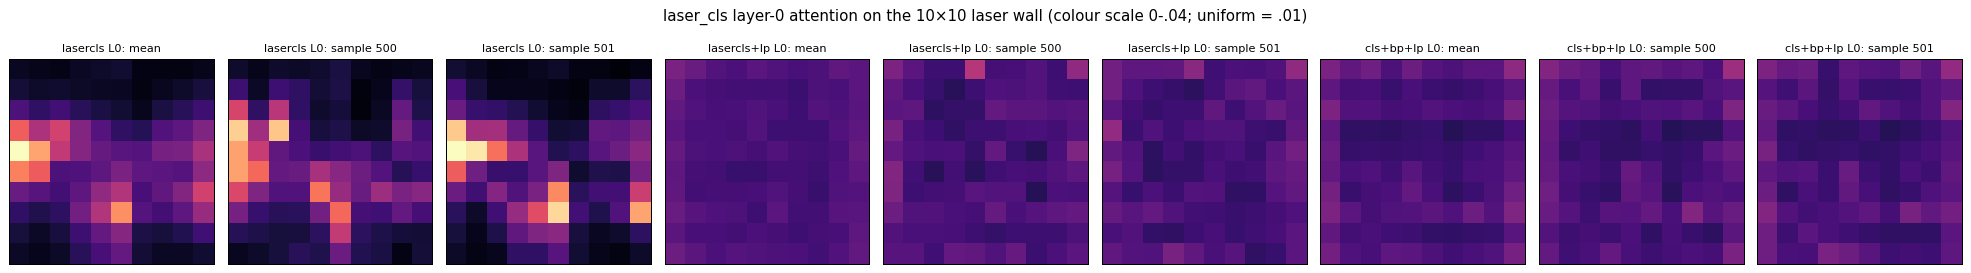

B2 · ID IoU@.08 when laser_cls's attention row is replaced by uniform weights (the laser tokens keep their own attention)


,as trained,uniform L0,uniform L1,uniform both
lasercls,0.549,0.223,0.383,0.194
lasercls+lp,0.569,0.351,0.545,0.330
cls+bp+lp,0.470,0.185,0.418,0.178


B3 · shuffle which laser slot each content token sits in (3 random permutations)


,IoU_as_trained,IoU_shuffled,latent_shift_over_sample_spread
ref,0.685,0.045,1.028
freqcls+bp,0.612,0.060,1.092
lasercls,0.549,0.362,0.518
lasercls+lp,0.569,0.458,0.376
cls+bp,0.433,0.178,0.736
cls+bp+lp,0.470,0.288,0.564


In [7]:
# B1 · how sharp is laser_cls attention?
B1 = []
for r in LCLS:
    a = O[r]["laser_attn"][ID]                                                              # (S,layers,H,100)
    ent = -(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(100)
    tot = a.var(0).sum(-1); dev = a - a.mean(0)
    for l in range(a.shape[1]):
        for h in range(a.shape[2]):
            B1.append(dict(run=r, layer=l, head=h, entropy=ent[:, l, h].mean().item(), max_w=a[:, l, h].max(-1).values.mean().item(), top10_mass=a[:, l, h].topk(10, -1).values.sum(-1).mean().item(),
                           tv_from_uniform=(a[:, l, h] - .01).abs().sum(-1).mean().item() / 2, tv_sample_vs_mean=dev[:, l, h].abs().sum(-1).mean().item() / 2))
B1 = pd.DataFrame(B1)
print("B1 · laser_cls attention over the 100 lasers (ID samples). entropy 1 = uniform; uniform max weight .01, top-10 mass .10"); display(B1.groupby(["run", "layer"], sort=False).mean().drop(columns="head").round(3))
fig, axs = plt.subplots(1, 3 * len(LCLS), figsize=(22, 3.2))
for j, r in enumerate(LCLS):
    la = O[r]["laser_attn"][ID][:, 0].mean(1)                                               # layer 0, mean over heads
    for k, (img, t) in enumerate([(la.mean(0), "mean"), (la[0], f"sample {ID[0]}"), (la[1], f"sample {ID[1]}")]):
        ax = axs[3 * j + k]; ax.imshow(img.view(10, 10), cmap="magma", vmin=0, vmax=.04); ax.set_title(f"{r} L0: {t}", fontsize=9); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("laser_cls layer-0 attention on the 10×10 laser wall (colour scale 0-.04; uniform = .01)"); plt.tight_layout(); plt.show()

# B2 · intervention: force laser_cls to read the lasers uniformly (mean pooling) in layer 0 / 1 / both
B2 = {}
for r in LCLS:
    B2[r] = {"as trained": iou(O[r]["mask"][ID].numpy(), ID).mean()}
    for u, nm in [((0,), "uniform L0"), ((1,), "uniform L1"), ((0, 1), "uniform both")]:
        B2[r][nm] = iou(run(M[r], ID, keep=["mask"], uniform=u)["mask"].numpy(), ID).mean()
B2 = pd.DataFrame(B2).T
print("B2 · ID IoU@.08 when laser_cls's attention row is replaced by uniform weights (the laser tokens keep their own attention)"); display(B2.round(3))

# B3 · does the laser identity/position travel with the content? shuffle the content between laser slots (each slot keeps its own laser embedding)
g = torch.Generator().manual_seed(0); PERMS = [torch.randperm(100, generator=g) for _ in range(3)]
B3 = {}
for r in LOAD:
    ious, dz = [], []
    for p in PERMS:
        o = run(M[r], ID, keep=["mask", "emb"], perm=p); ious.append(iou(o["mask"].numpy(), ID).mean())
        e0 = O[r]["emb"][ID]; dz.append(((o["emb"] - e0).norm(dim=1) / (e0 - e0.mean(0)).norm(dim=1).mean()).mean().item())
    B3[r] = dict(IoU_as_trained=iou(O[r]["mask"][ID].numpy(), ID).mean(), IoU_shuffled=np.mean(ious), latent_shift_over_sample_spread=np.mean(dz))
B3 = pd.DataFrame(B3).T
print("B3 · shuffle which laser slot each content token sits in (3 random permutations)"); display(B3.round(3))

**B4 · folding test**: explain the 128-d cls output linearly from (a) the laser-averaged laser-stage input (128 numbers), (b) mean + sd, (c) all 100 tokens (12,800).
**B5 · where is the information lost?** The same probes from (a) the 100 tokens the laser stage receives and (b) the 1024-d latent. Targets common to all models: each laser's
18 band energies (1,800 targets), the per-laser loudness pattern over the wall (sample mean removed), CoM, mask PCs. (12,800 features vs 500 training rows: the token-side R² is a lower bound.)

B4 · folding test on the laser side (R² of the cls output, ID samples)


,cls_R2_from_mean_tok,cls_R2_from_mean_and_sd,cls_R2_from_all_tokens,mean/all
lasercls,0.674,0.736,0.840,0.802
lasercls+lp,0.819,0.831,0.826,0.991
cls+bp+lp,0.841,0.859,0.875,0.961


B5 · linear probes from the 100 laser-stage input tokens vs from the 1024-d latent (fit train, R² on ID)


,tokens:CoM_R2,tokens:mask32_R2,tokens:wall_pattern_R2,tokens:laser×band_R2,latent:CoM_R2,latent:mask32_R2,latent:wall_pattern_R2,latent:laser×band_R2
ref,0.657,0.166,0.789,0.847,0.824,0.248,0.723,0.770
freqcls+bp,0.719,0.152,0.808,0.838,0.803,0.195,0.760,0.772
lasercls,0.648,0.159,0.790,0.841,0.828,0.121,0.574,0.582
lasercls+lp,0.667,0.156,0.801,0.859,0.909,0.157,0.556,0.541
cls+bp,0.694,0.142,0.789,0.827,0.787,0.100,0.582,0.617
cls+bp+lp,0.723,0.142,0.810,0.837,0.878,0.129,0.565,0.530


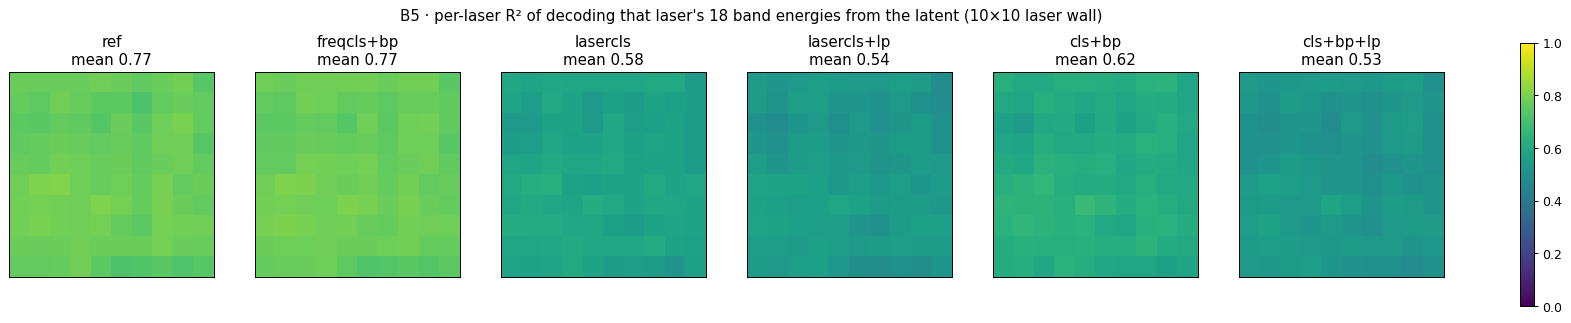

In [8]:
# B4 · is the cls a mean of the laser tokens? explain the 128-d cls output from (a) the laser-averaged input tokens (128 numbers) or (b) all 100 tokens (12,800)
B4 = {}
for r in LCLS:
    tok, c = O[r]["tok"], O[r]["c"]
    _, r_mean = probe(tok.mean(1), c, TR, ID); _, r_full = probe(tok.flatten(1), c, TR, ID)
    _, r_ms = probe(torch.cat([tok.mean(1), tok.std(1)], 1), c, TR, ID)
    B4[r] = dict(cls_R2_from_mean_tok=r_mean.mean().item(), cls_R2_from_mean_and_sd=r_ms.mean().item(), cls_R2_from_all_tokens=r_full.mean().item())
B4 = pd.DataFrame(B4).T; B4["mean/all"] = B4.cls_R2_from_mean_tok / B4.cls_R2_from_all_tokens
print("B4 · folding test on the laser side (R² of the cls output, ID samples)"); display(B4.round(3))

# B5 · where is information lost: before the laser stage (in the 100 tokens) or in the pooling (cls / flatten)?
#      same probes from (a) all 100 laser-stage input tokens, (b) the 1024-d latent; targets common to every model
energy = O["ref"]["energy"]                                                                  # (N,100,18) input, the same for every model
lmap = energy.mean(-1); lmap_spec = lmap - lmap.mean(1, keepdim=True)                       # per-laser loudness; its pattern over the wall (sample mean removed)
B5, MAPS = {}, {}
for r in LOAD:
    row = {}
    for src, F_ in [("tokens", O[r]["tok"].flatten(1)), ("latent", O[r]["emb"])]:
        pc, r2c = probe(F_, com, trn1, idn1); _, r2m = probe(F_, mask_pc, TR, ID); _, r2l = probe(F_, lmap_spec, TR, ID)
        _, r2e = probe(F_, energy.flatten(1), TR, ID)
        row |= {f"{src}:CoM_R2": r2c.mean().item(), f"{src}:mask32_R2": r2m.mean().item(), f"{src}:wall_pattern_R2": r2l.mean().item(), f"{src}:laser×band_R2": r2e.mean().item()}
        if src == "latent": MAPS[r] = r2e.view(100, 18).mean(1)
    B5[r] = row
B5 = pd.DataFrame(B5).T
print("B5 · linear probes from the 100 laser-stage input tokens vs from the 1024-d latent (fit train, R² on ID)"); display(B5.round(3))
fig, axs = plt.subplots(1, len(LOAD), figsize=(22, 3.8))
for ax, r in zip(axs, LOAD):
    im = ax.imshow(MAPS[r].view(10, 10).clamp(0, 1), cmap="viridis", vmin=0, vmax=1); ax.set_title(f"{r}\nmean {MAPS[r].mean():.2f}"); ax.set_xticks([]); ax.set_yticks([])
plt.colorbar(im, ax=axs, fraction=.015); plt.suptitle("B5 · per-laser R² of decoding that laser's 18 band energies from the latent (10×10 laser wall)"); plt.show()

## C · is it purely model size?
**C1** where the parameters are: the laser_cls runs lose exactly ref's 13.1M flatten readout (100 untied 128×1024 blocks). **C2 (causal)**: cut ref's flatten readout to rank k
(plain SVD of the weight, no retraining) and decode — this is a 12,800 → k → 1024 factorized per-laser readout with (12,800 + 1024)·k params. Also ref's latent cut to its top-k
data directions, with the B5 probes on it. **C3** ID over training, vs params, vs train fit.

C1 · parameters (M)


,freq stage,laser blocks,laser readout (to_emb / cls),P_l (laser_proj),laser emb/pos,laser pos,decoder,aux heads,total
ref,0.74,0.4,13.11,0.00,0.01,0.0,14.34,6.32,34.92
freqcls,0.43,0.4,13.11,0.00,0.01,0.0,14.34,6.32,34.61
freqcls+bp,0.72,0.4,13.11,0.00,0.01,0.0,14.34,6.32,34.90
lasercls,0.74,0.4,0.13,0.00,0.01,0.0,14.34,6.32,21.95
lasercls+lp,0.74,0.4,0.13,1.65,0.01,0.0,14.34,6.32,23.60
cls,0.43,0.4,0.13,0.00,0.01,0.0,14.34,6.32,21.63
cls+bp,0.72,0.4,0.13,0.00,0.01,0.0,14.34,6.32,21.92
cls+lp,0.43,0.4,0.13,1.65,0.01,0.0,14.34,6.32,23.29
cls+bp+lp,0.72,0.4,0.13,1.65,0.01,0.0,14.34,6.32,23.57


C2 · ref's flatten readout at rank k (full: 12800→1024, 13.1M; singular values: top-128 hold 0.29 of the weight energy)


,params_if_factorized_M,IoU_weight_rank_k,IoU_data_rank_k,laser_band_R2,wall_pattern_R2,mask32_R2
k,,,,,,
32,0.442,0.579,0.501,0.597,0.606,0.160
64,0.885,0.638,0.625,0.662,0.669,0.211
128,1.769,0.658,0.669,0.709,0.705,0.231
256,3.539,0.666,0.678,0.730,0.720,0.243
512,7.078,0.678,NaN,0.770,0.723,0.248


for comparison, laser_cls latents: {'lasercls': {'IoU': np.float64(0.549), 'laser_band_R2': np.float64(0.582), 'wall': np.float64(0.574)}, 'lasercls+lp': {'IoU': np.float64(0.569), 'laser_band_R2': np.float64(0.541), 'wall': np.float64(0.556)}, 'cls+bp+lp': {'IoU': np.float64(0.47), 'laser_band_R2': np.float64(0.53), 'wall': np.float64(0.565)}}


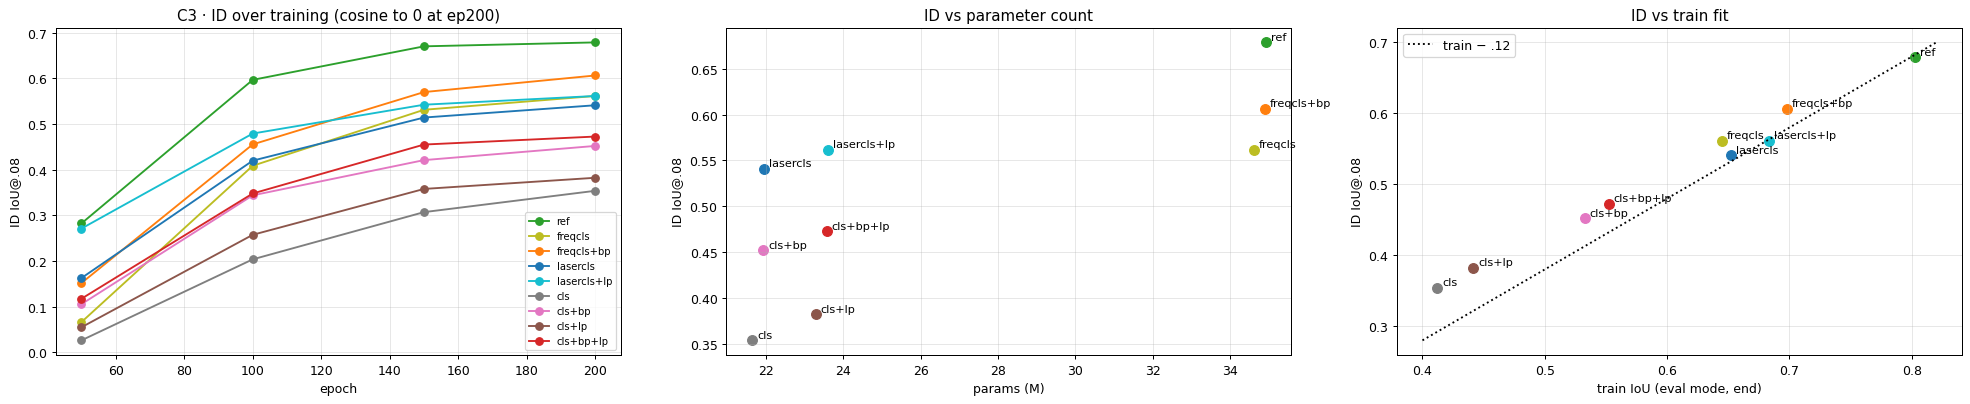

In [9]:
# C1 · where the parameters are
parts = {"freq stage": "freq_enc.", "laser blocks": "laser_enc.lasers.", "laser readout (to_emb / cls)": "laser_enc.to_emb", "P_l (laser_proj)": "encoder.proj_",
         "laser emb/pos": "encoder.laser_emb", "laser pos": "encoder.laser_pos", "decoder": "decoder.", "aux heads": "_head."}
C1 = pd.DataFrame({r: {k: n_params(SD[r], p) / 1e6 for k, p in parts.items()} | {"total": n_params(SD[r]) / 1e6} for r in GRID}).T
print("C1 · parameters (M)"); display(C1.round(2))

# C2 · ref's 12,800×1024 readout, cut to rank k (plain weight SVD), decoded; and the probes of A3/B5 on ref's latent cut to its top-k data directions
m = M["ref"]; Wf = m.encoder.laser_enc.to_emb[2].weight.detach().cpu(); bf = m.encoder.laser_enc.to_emb[2].bias.detach().cpu()
U, s, Vt = torch.linalg.svd(Wf.double(), full_matrices=False); U, s, Vt = U.float(), s.float(), Vt.float()
hid = torch.cat([m.encoder.laser_enc.to_emb[1](m.encoder.laser_enc.to_emb[0](O["ref"]["ztok"][i:i + 100].to(DEV))).cpu() for i in range(0, N, 100)])  # (N,12800) LN'd flattened tokens
assert torch.allclose(hid @ Wf.T + bf, O["ref"]["emb"], atol=1e-3)
C2 = {}
mu, V, _ = pca(O["ref"]["emb"], TR)
for k in [32, 64, 128, 256, 512]:
    Zw = (hid @ Vt[:k].T * s[:k]) @ U[:, :k].T + bf
    with torch.no_grad(): P = torch.cat([m.decoder(Zw[i:i + 100].to(DEV))[:, 0].sigmoid().cpu() for i in range(0, N, 100)]).numpy()
    Zd = mu + (O["ref"]["emb"] - mu) @ V[:k].T @ V[:k] if k <= len(V) else O["ref"]["emb"]
    _, r2e = probe(Zd, energy.flatten(1), TR, ID); _, r2l = probe(Zd, lmap_spec, TR, ID); _, r2m = probe(Zd, mask_pc, TR, ID)
    C2[k] = dict(params_if_factorized_M=(12800 * k + k * 1024) / 1e6, IoU_weight_rank_k=iou(P[ID], ID).mean(), IoU_data_rank_k=A2.loc["ref"].get(k, np.nan),
                 laser_band_R2=r2e.mean().item(), wall_pattern_R2=r2l.mean().item(), mask32_R2=r2m.mean().item())
C2 = pd.DataFrame(C2).T; C2.index.name = "k"
print(f"C2 · ref's flatten readout at rank k (full: {Wf.shape[1]}→{Wf.shape[0]}, 13.1M; singular values: top-128 hold {(s[:128]**2).sum() / (s**2).sum():.2f} of the weight energy)"); display(C2.round(3))
print("for comparison, laser_cls latents:", {r: dict(IoU=round(A2.loc[r, 128], 3), laser_band_R2=round(B5.loc[r, 'latent:laser×band_R2'], 3), wall=round(B5.loc[r, 'latent:wall_pattern_R2'], 3)) for r in LCLS})

# C3 · fitting: train IoU vs ID, and ID over training
fig, axs = plt.subplots(1, 3, figsize=(22, 4.6))
for r in GRID:
    e, v = zip(*[(ep, CURVE[r][ep][0]) for ep in (50, 100, 150, 200)]); axs[0].plot(e, v, "o-", color=COL[r], label=r)
    axs[1].scatter(C1.loc[r, "total"], T.loc[r, "ID"], color=COL[r], s=60); axs[1].annotate(r, (C1.loc[r, "total"], T.loc[r, "ID"]), fontsize=9, xytext=(4, 2), textcoords="offset points")
    axs[2].scatter(T.loc[r, "train_IoU"], T.loc[r, "ID"], color=COL[r], s=60); axs[2].annotate(r, (T.loc[r, "train_IoU"], T.loc[r, "ID"]), fontsize=9, xytext=(4, 2), textcoords="offset points")
x = np.array([.4, .82]); axs[2].plot(x, x - .12, "k:", label="train − .12"); axs[2].legend()
axs[0].set(xlabel="epoch", ylabel="ID IoU@.08", title="C3 · ID over training (cosine to 0 at ep200)"); axs[0].legend(fontsize=8)
axs[1].set(xlabel="params (M)", ylabel="ID IoU@.08", title="ID vs parameter count"); axs[2].set(xlabel="train IoU (eval mode, end)", ylabel="ID IoU@.08", title="ID vs train fit")
for ax in axs: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## D · failure pattern vs ref (all saved ep200 eval samples)
Per category; then per sample: CoM error of the predicted mask, **shape IoU** (IoU after moving the prediction onto the true CoM: removes location error), under-painting (missed px / true px),
over-painting (extra px / true px), median predicted/true area.

D1 · IoU@.08 per category (ep200 eval outputs, all samples)


,ref,freqcls+bp,lasercls,lasercls+lp,cls+bp+lp,n,Δ freqcls+bp,Δ lasercls,Δ lasercls+lp,Δ cls+bp+lp
group,,,,,,,,,,
id,0.719,0.648,0.588,0.606,0.518,2191,-0.071,-0.132,-0.114,-0.201
multiple,0.393,0.310,0.213,0.249,0.150,310,-0.083,-0.179,-0.144,-0.243
unseen-position,0.644,0.582,0.538,0.442,0.430,197,-0.063,-0.107,-0.203,-0.215
rotated,0.552,0.505,0.423,0.451,0.346,166,-0.048,-0.129,-0.102,-0.207
cylinder,0.132,0.107,0.086,0.097,0.076,331,-0.025,-0.046,-0.036,-0.057
unseen-object,0.578,0.540,0.490,0.494,0.453,550,-0.038,-0.087,-0.084,-0.125
unseen-speaker,0.372,0.317,0.319,0.259,0.252,85,-0.056,-0.054,-0.114,-0.120
unseen-laser,0.208,0.183,0.177,0.136,0.134,192,-0.025,-0.031,-0.072,-0.074
lid,0.075,0.065,0.052,0.029,0.056,83,-0.010,-0.022,-0.045,-0.019


D2 · failure pattern: shape_iou = IoU after moving the prediction onto the true CoM; under/over = missed / extra pixels as a fraction of the true area; area_ratio = median pred/true area


,,iou,shape_iou,com_err,miss,under,over,area_ratio
id,ref,0.719,0.817,0.018,0.005,0.109,0.280,1.143
multiple,ref,0.393,0.239,0.090,0.006,0.415,0.549,1.152
unseen-position,ref,0.644,0.802,0.026,0.000,0.208,0.272,1.071
OOD,ref,0.377,0.550,0.079,0.199,0.405,1.383,1.167
id,freqcls+bp,0.648,0.759,0.024,0.010,0.125,0.423,1.254
multiple,freqcls+bp,0.310,0.201,0.100,0.023,0.498,0.689,1.167
unseen-position,freqcls+bp,0.582,0.763,0.032,0.000,0.223,0.394,1.167
OOD,freqcls+bp,0.344,0.523,0.089,0.210,0.428,1.603,1.265
id,lasercls,0.588,0.761,0.033,0.024,0.190,0.482,1.253
multiple,lasercls,0.213,0.145,0.109,0.084,0.633,0.830,1.215


D3 · paired vs ref on single-object ID samples


,dIoU,dShapeIoU,dCoM_err,frac_samples_worse,worse_where_ref_com_err_lt_05,dUnder,dOver
freqcls+bp,-0.071,-0.058,0.006,0.554,-0.074,0.016,0.144
lasercls,-0.132,-0.057,0.015,0.683,-0.135,0.081,0.203
lasercls+lp,-0.114,-0.042,0.013,0.649,-0.117,0.069,0.165
cls+bp+lp,-0.201,-0.093,0.024,0.827,-0.207,0.127,0.326


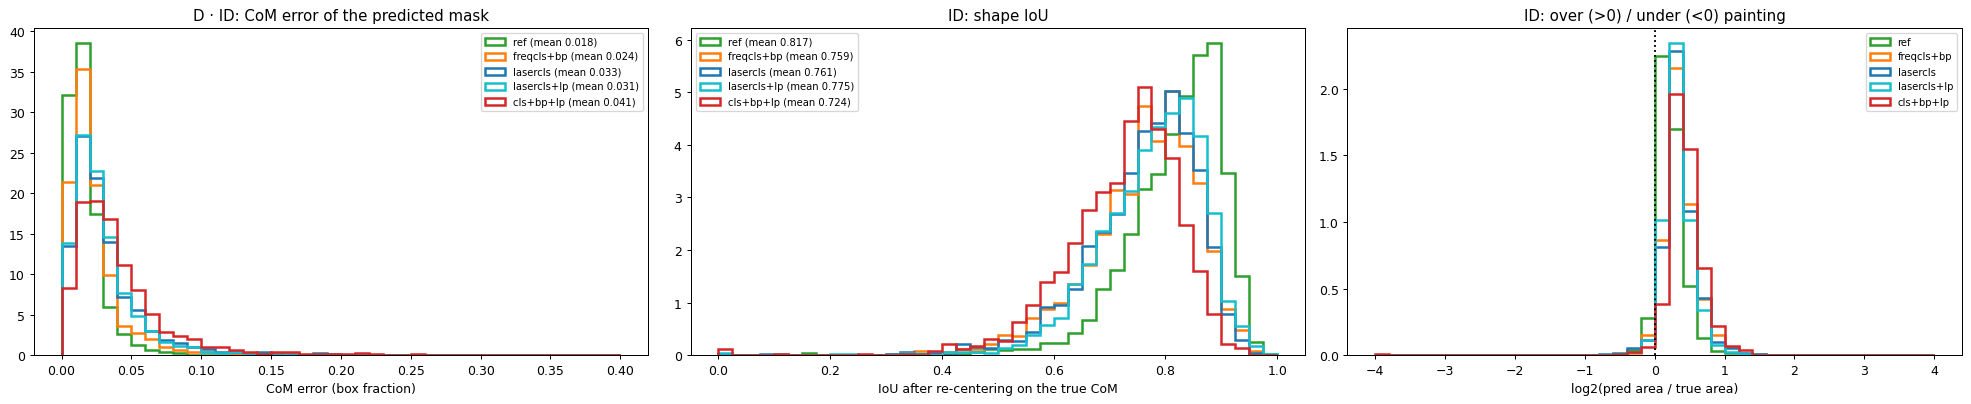

In [10]:
D_RUNS = ["ref", "freqcls+bp", "lasercls", "lasercls+lp", "cls+bp+lp"]
for r in D_RUNS: EV[r]["group"] = [CAT.get((b, s)) for b, s in zip(EV[r].box, EV[r].split)]
ORDER = ["id", "multiple", "unseen-position", *OOD]
D1 = pd.DataFrame({r: EV[r].groupby("group").iou.mean() for r in D_RUNS}).loc[ORDER]
D1["n"] = EV["ref"].groupby("group").size().loc[ORDER]
for r in D_RUNS[1:]: D1[f"Δ {r}"] = D1[r] - D1["ref"]
print("D1 · IoU@.08 per category (ep200 eval outputs, all samples)"); display(D1.round(3))

met = ["iou", "shape_iou", "com_err", "miss", "under", "over", "area_ratio"]
D2 = {}
for r in D_RUNS:
    e = EV[r]
    for g in ["id", "multiple", "unseen-position", "OOD"]:
        sel = e[e.group.isin(OOD)] if g == "OOD" else e[e.group == g]
        D2[(g, r)] = {k: (sel[k].median() if k == "area_ratio" else sel[k].mean()) for k in met}
D2 = pd.DataFrame(D2).T
print("D2 · failure pattern: shape_iou = IoU after moving the prediction onto the true CoM; under/over = missed / extra pixels as a fraction of the true area; area_ratio = median pred/true area")
display(D2.round(3))

# how much of each model's ID loss vs ref is location vs shape? paired per sample (single-object ID samples)
e0 = EV["ref"].set_index(["box", "split", "pos", EV["ref"].groupby(["box", "split", "pos"]).cumcount()])
D3 = {}
for r in D_RUNS[1:]:
    e1 = EV[r].set_index(["box", "split", "pos", EV[r].groupby(["box", "split", "pos"]).cumcount()]); j = e0.join(e1, rsuffix="_r", how="inner"); j = j[j.group == "id"]
    D3[r] = dict(dIoU=(j.iou_r - j.iou).mean(), dShapeIoU=(j.shape_iou_r - j.shape_iou).mean(), dCoM_err=(j.com_err_r - j.com_err).mean(),
                 frac_samples_worse=(j.iou_r < j.iou - .05).mean(), worse_where_ref_com_err_lt_05=(j.iou_r - j.iou)[j.com_err < .05].mean(),
                 dUnder=(j.under_r - j.under).mean(), dOver=(j.over_r - j.over).mean())
D3 = pd.DataFrame(D3).T
print("D3 · paired vs ref on single-object ID samples"); display(D3.round(3))

fig, axs = plt.subplots(1, 3, figsize=(22, 4.6))
bins = np.linspace(0, .4, 41)
for r in D_RUNS:
    e = EV[r][EV[r].group == "id"]
    axs[0].hist(e.com_err.dropna(), bins, histtype="step", lw=2, color=COL[r], label=f"{r} (mean {e.com_err.mean():.3f})", density=True)
    axs[1].hist(e.shape_iou, np.linspace(0, 1, 41), histtype="step", lw=2, color=COL[r], label=f"{r} (mean {e.shape_iou.mean():.3f})", density=True)
    axs[2].hist(np.log2(e.area_ratio.clip(1 / 16, 16)), np.linspace(-4, 4, 41), histtype="step", lw=2, color=COL[r], label=r, density=True)
axs[0].set(xlabel="CoM error (box fraction)", title="D · ID: CoM error of the predicted mask"); axs[1].set(xlabel="IoU after re-centering on the true CoM", title="ID: shape IoU")
axs[2].set(xlabel="log2(pred area / true area)", title="ID: over (>0) / under (<0) painting"); axs[2].axvline(0, color="k", ls=":")
for ax in axs: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## E · the combination: what `freq_cls` hands to `laser_cls`
nb116's token metrics on the per-laser token out of the freq stage (`raw`), for the laser-flatten runs (ref, freqcls+bp) and the laser_cls runs (lasercls, lasercls+lp, cls+bp, cls+bp+lp).
`tok_sample_rms_over_fixed_rms` = size of the sample-dependent part of the laser-stage input vs the fixed per-laser part (laser embedding, + P_l bias): how much of what `laser_cls`
reads actually changes with the input. (`tok_eff_rank` is inflated to ~100 by P_l, which puts each laser in its own subspace.)

In [11]:
def center(Tk): return (Tk - Tk.mean(0, keepdim=True)).flatten(0, 1).float()             # remove each laser's mean over samples, rows = (sample, laser)
def probe_rows(Xf, Yf, n_samples, lam=1e-2):
    n = int(n_samples * .8) * 100; return r2(ridge_fit(Xf[:n], Yf[:n], lam)(Xf[n:]), Yf[n:])
def eff_rank(dev): sv = torch.linalg.svdvals(dev.flatten(0, 1)) ** 2; return (sv.sum() ** 2 / (sv ** 2).sum()).item()
E_RUNS = ["ref", "lasercls", "lasercls+lp", "freqcls+bp", "cls+bp", "cls+bp+lp"]
xn_id = ((X[ID] - SD["ref"]["encoder.cum_mean"][BOX[ID]]) * SD["ref"]["encoder.cum_std"][BOX[ID]]).reshape(len(ID), 100, 18, 130)  # the input (same stats in every run)
e_band, full, folded = center(xn_id.mean(-1)), center(xn_id.flatten(2)), center(xn_id.mean(2))
del xn_id
E = {}
for r in E_RUNS:
    Rw = O[r]["raw"][ID].double(); tok = center(Rw)
    f_r2, a_r2 = probe_rows(full, tok, len(ID)).mean().item(), probe_rows(folded, tok, len(ID)).mean().item()
    dev = Rw - Rw.mean(0, keepdim=True); spec = dev - dev.mean(1, keepdim=True)
    Tt = O[r]["tok"][ID].double(); dT = Tt - Tt.mean(0, keepdim=True); lsr = Tt.mean(0)                     # laser-stage input: sample part, fixed per-laser part
    E[r] = dict(raw_band_energy_R2=probe_rows(tok, e_band, len(ID)).mean().item(), raw_folded_over_full=a_r2 / f_r2,
                raw_sample_dep_frac=(dev.pow(2).sum() / (Rw - Rw.mean((0, 1), keepdim=True)).pow(2).sum()).item(), raw_eff_rank=eff_rank(dev),
                raw_laser_specific_share=(spec.pow(2).sum() / dev.pow(2).sum()).item(),
                tok_sample_rms_over_fixed_rms=(dT.pow(2).sum(-1).mean().sqrt() / (lsr - lsr.mean(0)).pow(2).sum(-1).mean().sqrt()).item(),
                tok_eff_rank=eff_rank(dT))
    if ARGS[r]["freq_cls"]: a = O[r]["freq_attn"][ID]; E[r]["freq_cls_entropy"] = (-(a * a.clamp_min(1e-12).log()).sum(-1) / math.log(18)).mean().item()
E = pd.DataFrame(E).T
print("E · raw = per-laser token out of the freq stage (nb116's metrics); tok = what the laser stage receives (after P_l and + laser embedding), ID samples")
display(E.round(3))

E · raw = per-laser token out of the freq stage (nb116's metrics); tok = what the laser stage receives (after P_l and + laser embedding), ID samples


,raw_band_energy_R2,raw_folded_over_full,raw_sample_dep_frac,raw_eff_rank,raw_laser_specific_share,tok_sample_rms_over_fixed_rms,tok_eff_rank,freq_cls_entropy
ref,0.666,0.119,0.871,34.538,0.735,2.334,34.538,NaN
lasercls,0.584,0.147,0.696,19.697,0.564,0.937,19.697,NaN
lasercls+lp,0.767,0.168,0.927,7.698,0.412,1.205,107.276,NaN
freqcls+bp,0.589,0.183,0.639,10.958,0.541,0.679,10.958,0.935
cls+bp,0.545,0.089,0.510,6.200,0.376,0.500,6.200,0.944
cls+bp+lp,0.610,0.185,0.669,7.376,0.412,0.470,101.369,0.942


## summary
**Not purely model size, and not the 128-d rank either. The information is lost in the pooling: `laser_cls` turns into a softmax mean of the 100 laser tokens,
and that mean keeps coarse location (CoM, area, object) but loses the fine per-laser pattern the decoder needs for exact masks.**

1. **Rank is not the bottleneck (A).** Ref's latent cut to its top-128 directions still decodes ID .669 (full .685); the laser_cls latents don't even use their 128
   dims (participation ratio 10–17 vs ref 27; 90% of variance in 15–31 directions vs 72) and saturate by k ≈ 64.
2. **The tokens going into the laser stage are as informative as ref's; the loss is at the pooling (B5).** Probing each laser's 18 band energies from the 100 laser-stage
   tokens: R² .83–.86 for every model. From the latent: ref .77 (ref cut to 128 dims: .71), laser_cls models .53–.58. Wall loudness pattern .72 vs .56–.57.
3. **What survives / what's lost (A3).** CoM is *better* linearly decodable from the laser_cls latents (R² .88–.91 vs ref .82), area and object identity are equal.
   What's lost is mask detail beyond the coarse blob: mask PCs 5–32 R² .07–.09 vs ref .19.
4. **With `laser_proj`, the cls is a mean (B1, B4).** Attention entropy .95–.98 of uniform in every layer/head (max weight .02–.03 vs .01 uniform); a linear fit from the
   *laser-averaged* tokens explains 99% (lasercls+lp) / 96% (cls+bp+lp) of what all 100 tokens explain. Without P_l (lasercls) attention is sharper (layer-0 entropy .70–.82,
   mean-only 80%): P_l moves laser identity into the content (slot shuffle keeps .458 of .569; ref collapses to .045), and attention goes flat. The small deviations from
   uniform still matter: forcing uniform layer-0 attention costs .22 (B2).
5. **Size (C).** All 9 runs sit on one line ID ≈ train IoU − .12: every [cls] variant **underfits** (train IoU .55–.70 vs ref .80), it does not overfit. Params do not order
   them (freqcls 34.6M ≈ lasercls 21.9M on ID). And ref's 13.1M readout is mostly unneeded: cutting its weight to rank 32 (a 0.44M factorized 12,800 → 32 → 1024 readout,
   no retraining) still gives .579 > lasercls+lp .569; rank 128 (1.77M) .658. What matters is a per-laser untied readout of the *final* laser tokens into a linear sum,
   not 13M parameters. +1.6M of P_l bought +.02 ID / +.03 train.
6. **Failure pattern (D).** lasercls+lp vs ref on single-object ID: IoU −.114, but shape IoU (recentred) only −.042, CoM error .018 → .031 (~1 px), over-painting +.17,
   under-painting +.07: masks are blurrier, larger and slightly off. Two-object scenes collapse most: .393 → .249 (lasercls+lp) / .150 (cls+bp+lp), miss rate .6% → 7% / 18%:
   one pooled vector can't hold two locations. Unseen positions: lasercls+lp −.20 (lasercls without P_l only −.11; P_l hurts unseen positions).
7. **The combination (E).** `laser_cls` alone already collapses the per-laser freq-stage token (eff. rank 34.5 → 19.7 → 7.7 with P_l), so `freq_cls` collapsing it too
   (cls+bp+lp: 7.4) adds little, which is why the costs are nearly additive. The −.016 interaction fits a weaker input: in cls+bp+lp the sample-dependent part of what
   `laser_cls` reads is .47× the fixed per-laser embedding (lasercls+lp 1.21, ref 2.33), and its attention is the least sample-dependent (TV to mean map .07–.12 vs .18–.38).

**Ranked fixes (each a cheap 200-ep ablation)**
1. **Low-rank per-laser flatten** (`--laser_readout lowrank --readout_rank 128`): flatten → Linear(12,800 → 128) → Linear(128 → 1024), no cls. 1.77M vs 13.1M (**−11.3M vs ref**,
   ≈ lasercls+lp's size). Post-hoc cut of ref predicts ≈ .66 ID; rank 64 (0.9M) ≈ .64. Run at equal params to lasercls+lp: this is the structure-vs-size test.
2. **cls + low-rank flatten** (`--laser_cls 1 --cls_flatten_rank 64`): latent = Linear(LN(cls)) + low-rank flatten of the final laser tokens; +0.9M over lasercls (−12.2M vs ref).
   Keeps a cls for the paper framing, restores the per-laser readout B5 says is missing.
3. **Spatial pooling readout** (`--laser_pool 2`): average the final tokens over 2×2 laser patches → 25 × 128 = 3,200 → Linear(→ 1024), 3.3M (−9.8M vs ref). Keeps *which region*;
   targets the two-object / fine-location failure.
4. **k readout tokens** (`--laser_cls 8`, concatenated 8 × 128 → 1024, +~1k params, −13M vs ref). Weak evidence: attention is flat with P_l and never sharpens, so k queries may all read
   the same mean; only worth it with region-biased queries / a per-token attention prior.
5. **Wider cls** (laser stage at d=512 with a 128 → 512 up-projection, ~+6M, −7M vs ref): low priority, since 128 dims suffice for ref (A2).
6. **Param-matched laser_cls** (pad the decoder/heads +11M): a control only; C predicts little gain.
Side note: drop `laser_proj` if keeping `laser_cls`: +.02 ID but −.09 on unseen positions vs lasercls.